<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Time Series II: Modeling

_Author: Tim Book_

---

### Learning Objectives
By the end of this lesson, students should be able to:
- Understand the Classical decomposition of a time series
- Describe the components of the ARIMA model and their significance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV

import statsmodels.api as sm
from itertools import product

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Data

Today's first dataset will be the average air temperature (F) recorded at Nottingham Castle recorded monthly from 1920 to 1939

In [2]:
nottem = pd.read_csv('https://raw.githubusercontent.com/Ch3ddarr/DSB-Unit-03/refs/heads/main/data/nottingham.csv')
nottem.date = pd.to_datetime(nottem.date)
nottem.set_index('date', inplace=True)
nottem.head()

/tmp/ipykernel_590/321264159.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  nottem.date = pd.to_datetime(nottem.date)


,temp
date,
1920-01-01,40.6
1920-02-01,40.8
1920-03-01,44.4
1920-04-01,46.7
1920-05-01,54.1


In [3]:
nottem.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 240 entries, 1920-01-01 to 1939-12-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    240 non-null    float64
dtypes: float64(1)
memory usage: 3.8 KB


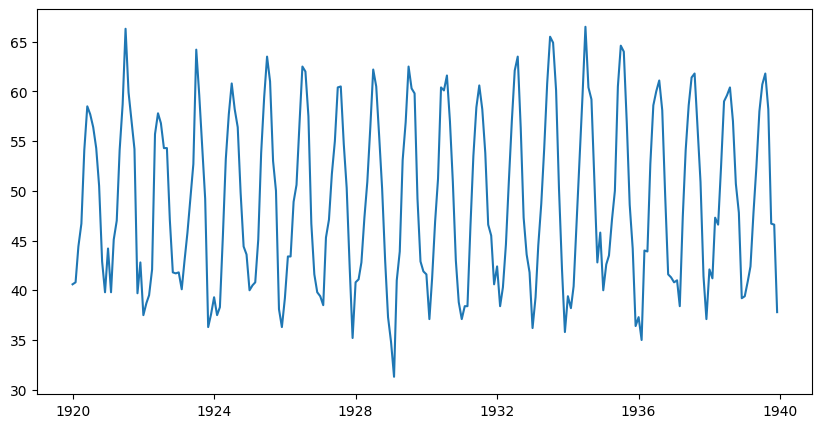

In [4]:
plt.figure(figsize=(10,5))
plt.plot(nottem);

**(THREAD):** Describe this time series. Is it stationary? Is there seasonality?

Check out the ACF plot, PACF plot, and the `statsmodels` decomposition below. Does this validate your opinions?

In [5]:
# Decomposition
#decomp = seasonal_decompose(nottem)
decomp = seasonal_decompose(x=nottem['temp'],period=12, model='additive')

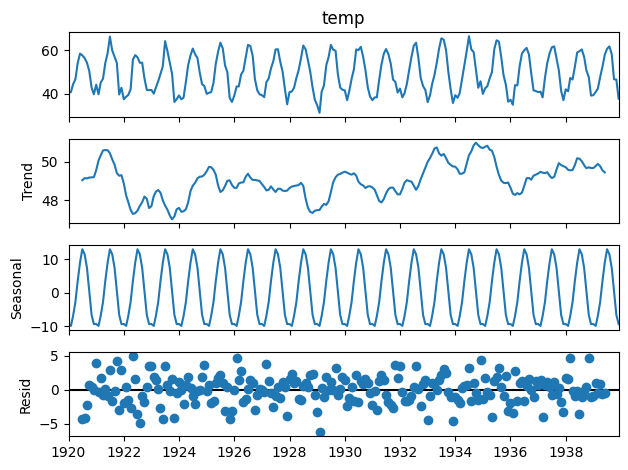

In [6]:
decomp.plot();

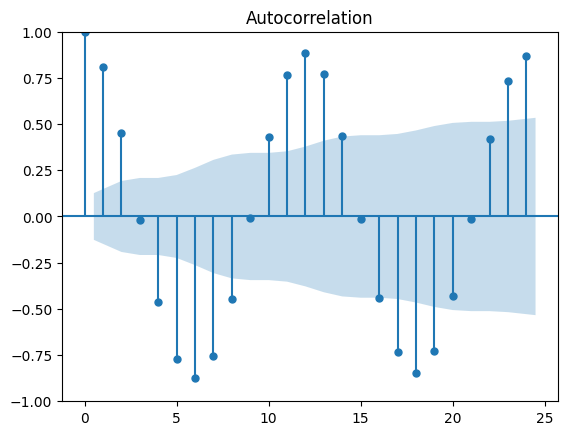

In [7]:
# ACF
plot_acf(nottem);

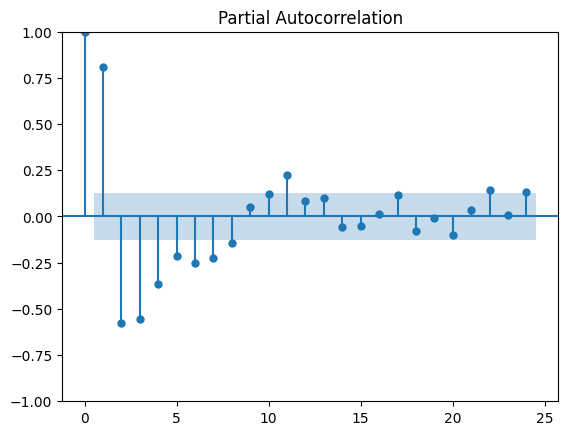

In [8]:
# PACF
plot_pacf(nottem);

# Model Prep

In [57]:
# rad sa profom
nottem['month'] = nottem.index.month
y_train, y_test = train_test_split(nottem, test_size=0.1, shuffle=False)

In [58]:
y_train.shape, y_test.shape

((216, 2), (24, 2))

In [59]:
# Do a train-test split holding out only 10% of our data unshuffled (why?)
#s samostalni rad
train, test = train_test_split(nottem, test_size=0.1, shuffle=False)

In [60]:
train.shape, test.shape

((216, 2), (24, 2))

# Create components
- $m_t$ : We'll assume no trend here and just let $\hat m_t = \bar y$
- $s_t$ : Since we have monthly data we'll just let $\hat s_t$ be the mean temperature per month with the trend removed.

In [61]:
#samostalno
mt = train.temp.mean()
train['detrended'] = train['temp'] - mt

In [62]:
train['month'] = train.index.month

In [63]:
st = train.groupby('month')['detrended'].mean()

In [64]:
test['month'] = test.index.month

In [65]:
test['seasonal'] = test['month'].map(st)

In [66]:
test.head()

,temp,month,seasonal
date,,,
1938-01-01,42.1,1,-9.373611
1938-02-01,41.2,2,-9.968056
1938-03-01,47.3,3,-7.051389
1938-04-01,46.6,4,-2.762500
1938-05-01,52.4,5,3.626389


,temp,month
date,,
1938-01-01,42.1,1
1938-02-01,41.2,2
1938-03-01,47.3,3
1938-04-01,46.6,4
1938-05-01,52.4,5


In [17]:
#prof
mt = y_train.temp.mean()

st = y_train.groupby('month', as_index=False).temp.mean()
st['seasonal'] = st.temp - mt
st.round(2)

,month,temp,seasonal
0,1,39.58,-9.37
1,2,38.98,-9.97
2,3,41.90,-7.05
3,4,46.19,-2.76
4,5,52.58,3.63
5,6,57.99,9.04
6,7,62.09,13.14
7,8,60.46,11.50
8,9,56.36,7.40
9,10,49.58,0.63


# Predictions
This might not _feel_ like a model, but we actually have enough to make predictions now. Let's merge the seasonal components back onto the testing data and add the trend back on. Those are our predictions!

In [18]:
y_test_pred = y_test.merge(st[['month', 'seasonal']], how='left')
y_test_pred['y_pred'] = mt + y_test_pred['seasonal']

In [19]:
y_test_pred

,temp,month,seasonal,y_pred
0,42.1,1,-9.373611,39.577778
1,41.2,2,-9.968056,38.983333
2,47.3,3,-7.051389,41.900000
3,46.6,4,-2.762500,46.188889
4,52.4,5,3.626389,52.577778
5,59.0,6,9.037500,57.988889
6,59.6,7,13.143056,62.094444
7,60.4,8,11.504167,60.455556
8,57.0,9,7.404167,56.355556
9,50.7,10,0.631944,49.583333


In [20]:
# Pretty good!
y_test_pred.index = y_test.index
y_test_pred

,temp,month,seasonal,y_pred
date,,,,
1938-01-01,42.1,1,-9.373611,39.577778
1938-02-01,41.2,2,-9.968056,38.983333
1938-03-01,47.3,3,-7.051389,41.900000
1938-04-01,46.6,4,-2.762500,46.188889
1938-05-01,52.4,5,3.626389,52.577778
1938-06-01,59.0,6,9.037500,57.988889
1938-07-01,59.6,7,13.143056,62.094444
1938-08-01,60.4,8,11.504167,60.455556
1938-09-01,57.0,9,7.404167,56.355556


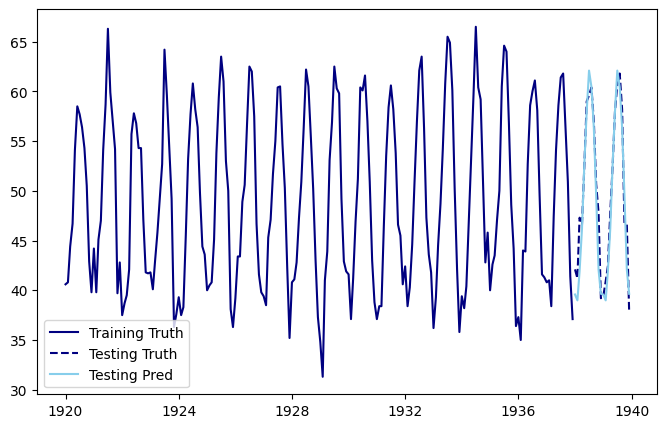

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(y_train.temp, c='navy', label='Training Truth')
plt.plot(y_test_pred.temp, c='navy', linestyle='--', label='Testing Truth')
plt.plot(y_test_pred.y_pred, c='skyblue', label='Testing Pred')

plt.legend();

# ARIMA with Airline Data
Our second dataset is monthly airline data from Box and Jenkins (1976).

In [22]:
air = pd.read_csv('https://raw.githubusercontent.com/Ch3ddarr/DSB-Unit-03/refs/heads/main/data/airline-passengers.csv', parse_dates=['Month'], index_col='Month', date_format='%Y-%m')

In [23]:
air.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


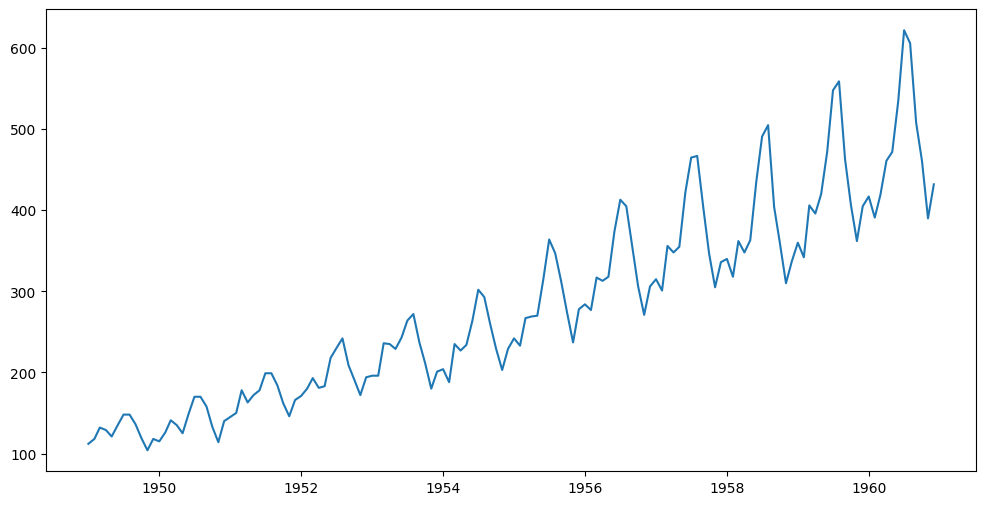

In [24]:
plt.figure(figsize=(12,6))
plt.plot(air);

**(THREAD):** Let's set aside the last 24 rows (two years) as testing data _without using the_ `train_test_split()` function!

In [25]:
h = 24
y_train = air.iloc[:-h]
y_test = air.iloc[-h:]

In [26]:
y_test.shape, y_train.shape

((24, 1), (120, 1))

## Stationarity with the ADF Test

Let's do some EDA to see how many diffs it takes to achieve stationarity. We'll also do an **Augmented Dickey-Fuller test** to be "official" about it.

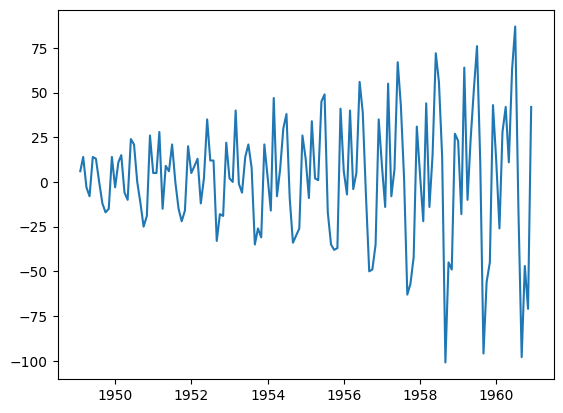

In [27]:
# Once is probably fine
plt.plot(air.diff());

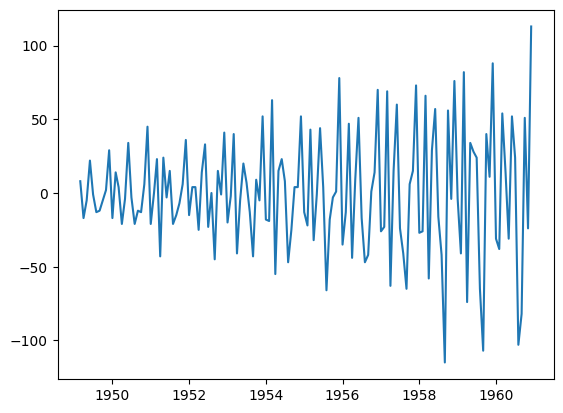

In [28]:
# Twice doesn't change much
plt.plot(air.diff().diff());

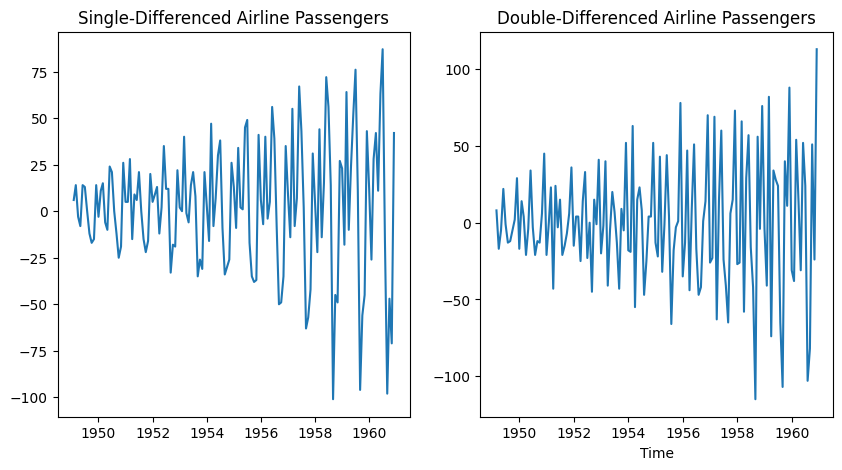

In [29]:
# We described previously that in a real machine learning pipeline, we don't actually need a distinct test for every scenario because the remedies to fix non-stationarity are very straightforward:
#1. If it fails the ADF (Has a Trend): Apply First-Order Differencing (df.diff()). This subtracts yesterday's value from today's value, flattening out the trend line.
#2. If it fails the KPSS (Has Seasonality): Apply Seasonal Differencing (df.diff(periods=12)). This subtracts last year's value from this year's value to strip out cyclical waves.
#3. If it has Changing Variance (Megaphone shape): Apply a Log Transform (np.log(df)) or a Box-Cox transformation. This compresses the large swings down to a uniform scale.

air_diff = air.diff()
air_ddiff = air.diff().diff()

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)

plt.plot(air_diff)
plt.title('Single-Differenced Airline Passengers')

plt.subplot(1,2,2)
plt.plot(air_ddiff)
plt.title('Double-Differenced Airline Passengers')

plt.xlabel('Time')
plt.show()

## The Augmented Dickey Fuller test
The technicalities are outside our scope, but you can read more about it [here](https://en.wikipedia.org/wiki/Augmented_Dickey%E2%80%93Fuller_test).

In short, we're testing:

$$
H_0: \text{not stationary} \\
H_A: \text{stationary}
$$

In [30]:
# Looks like we may have to diff twice to be stationary!
adf_diff1, pval_diff1, *_ = adfuller(air.diff().dropna(), result_object=True)
adf_diff2, pval_diff2, *_ = adfuller(air.diff().diff().dropna(), result_object=True)

print(f"diff-d once p-value = {pval_diff1:.40f}\ndiff'd twice p-values = {pval_diff2:.40f}\n")


diff-d once p-value = 0.0542132902838255228972208499271800974384
diff'd twice p-values = 0.0000000000000000000000000000273289185001



In [31]:
adf_diff1, pval_diff1, *_ = adfuller(air.diff().dropna(), result_object=True)
adf_diff2, pval_diff2, *_ = adfuller(air.diff().diff().dropna(), result_object=True)

print(f"diff'd once  p-value = {pval_diff1:.40f}\ndiff'd twice p-value = {pval_diff2:.40f}\n")
# Looks like we may have to diff twice to be stationary!

if (pval_diff1 <= 0.05):
  print(f"ADF Test: the Single-Differenced Airline Passengers data is Stationary!")
else:
  print(f"ADF Test: the Single-Differenced Airline Passengers data is non-Stationary!")



if (pval_diff2 <= 0.05):
  print(f"ADF Test: the Double-Differenced Airline Passengers data is Stationary!")
else:
  print(f"ADF Test: the Double-Differenced Airline Passengers data is non-Stationary!")

diff'd once  p-value = 0.0542132902838255228972208499271800974384
diff'd twice p-value = 0.0000000000000000000000000000273289185001

ADF Test: the Single-Differenced Airline Passengers data is non-Stationary!
ADF Test: the Double-Differenced Airline Passengers data is Stationary!


## First Attempt: ARIMA(1, 2, 1)

Let's use `statsmodels` to fit an ARIMA(1, 2, 1) model.

In [32]:
model = ARIMA(y_train, order=(1,2,1)).fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [33]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             Passengers   No. Observations:                  120
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -560.986
Date:                Mon, 26 Oct 2026   AIC                           1127.973
Time:                        13:17:03   BIC                           1136.285
Sample:                    01-01-1949   HQIC                          1131.348
                         - 12-01-1958                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2938      0.110      2.665      0.008       0.078       0.510
ma.L1         -0.9998      6.133     -0.163      0.871     -13.020      11.020
sigma2       761.4614   4700.081      0.162      0.871   -8450.527    9973.450
===================================================================================
Ljung-Box (L1) (Q):                   0.38   Jarque-Bera (JB):                 5.62
Prob(Q):                              0.54   Prob(JB):                         0.06
Heteroskedasticity (H):               7.13   Skew:                            -0.07
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.06
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Evaluation

You might notice a lack of $R^2$! The preferred evaluation metric is the [Akaike Information Criterion (AIC)](https://en.wikipedia.org/wiki/Akaike_information_criterion). It won't make sense at first glance - but it's an error metric where lower is better, and it's based off the specific loss function of the ARIMA model.

**TL;DR:** We'll use AIC as our model evaluation of choice. Lower is better!

In [34]:
model.aic

np.float64(1127.9726162094405)

## "Grid Search"

Since we're using `statsmodels`, we can actually use `GridSearchCV`, but that's ok! We can make our own loop.

In [39]:
%time

p_array = np.arange(8)
d_array = np.arange(2)
q_array = np.arange(13)

results = []

for p, d, q in product(p_array, d_array, q_array):
  model = ARIMA(y_train, order=(p,d,q)).fit()
  results.append((p,d,q,model.aic))

#%time


CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 5.72 µs


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

KeyboardInterrupt: 

In [37]:
df_res = pd.DataFrame(results, columns=['p','q','aic'])
df_res.sort_values('aic').head(10)

ValueError: 3 columns passed, passed data had 4 columns

In [ ]:
best_p, best_q = df.res.sort_values('aic', ascending = True).iloc[0]['p','q']

In [ ]:
# Best model summary

# Predictions and Evaluation

There appears to be some series underestimation - this is normal for a model like this that appears to have rising variance over time!

# Conclusions and Takeaways
- You can use simple heuristics rather than ML models to make forecasts on certain scenarios
- The ARIMA model is the base form of models for modeling time series
- There are many variants and additions to the ARIMA model!
- TS modeling works best when the past predicts future. Weather, sales, and deaths - yes! The stock market - no!